In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hospital_data.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (12000, 12)


,Patient_ID,Appointment_Date,Appointment_Time,Arrival_Time,Department,Doctor_ID,Patient_Type,Queue_Length,Doctors_Available,Appointments_Count,Consultation_Duration_Min,Waiting_Time_Minutes
0,P05732,2026-01-01,08:00,07:54,ENT,DOC013,New,11,3,20,21,20
1,P02024,2026-01-01,09:10,09:33,General Medicine,DOC016,Returning,8,1,31,12,28
2,P00180,2026-01-01,09:30,09:46,Orthopedics,DOC016,New,7,1,27,25,34
3,P03650,2026-01-01,10:00,09:54,General Medicine,DOC003,New,10,2,25,16,23
4,P03679,2026-01-01,10:20,10:17,Gynecology,DOC013,Returning,12,3,29,22,15


In [18]:
print(df.describe())

       Queue_Length  Doctors_Available  Appointments_Count  \
count  12000.000000       12000.000000        12000.000000   
mean      11.951667           2.945167           24.994083   
std        3.439183           1.113222            5.019029   
min        1.000000           1.000000            8.000000   
25%       10.000000           2.000000           21.000000   
50%       12.000000           3.000000           25.000000   
75%       14.000000           4.000000           28.000000   
max       27.000000           5.000000           48.000000   

       Consultation_Duration_Min  Waiting_Time_Minutes  
count               12000.000000          12000.000000  
mean                   19.628500             19.570917  
std                     4.202931             10.448616  
min                    10.000000              5.000000  
25%                    17.000000             11.000000  
50%                    20.000000             19.000000  
75%                    23.000000          

In [19]:
print(df["Department"].value_counts())

Department
ENT                 1541
Cardiology          1528
Dermatology         1509
General Medicine    1502
Gynecology          1500
Pediatrics          1493
Orthopedics         1465
Neurology           1462
Name: count, dtype: int64


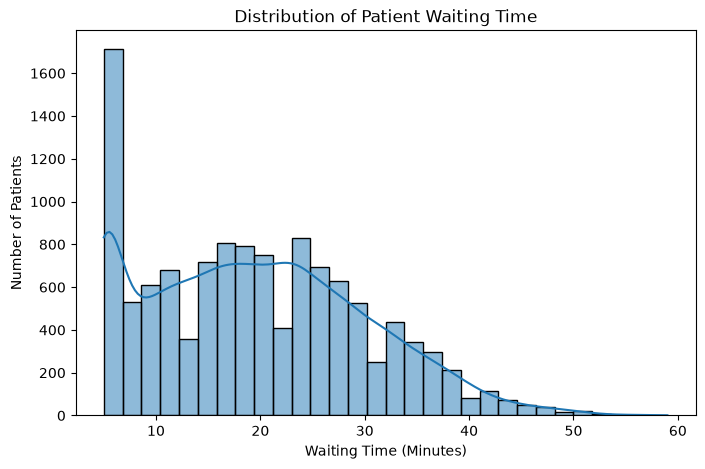

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Waiting_Time_Minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Patient Waiting Time")
plt.xlabel("Waiting Time (Minutes)")
plt.ylabel("Number of Patients")

plt.show()

In [21]:
department_wait = (
    df.groupby("Department")["Waiting_Time_Minutes"]
    .mean()
    .sort_values(ascending=False)
)

print(department_wait)

Department
Neurology           22.334473
Cardiology          21.340314
Orthopedics         20.057338
Gynecology          20.003333
Pediatrics          19.314133
Dermatology         18.565275
ENT                 18.044127
General Medicine    17.006658
Name: Waiting_Time_Minutes, dtype: float64


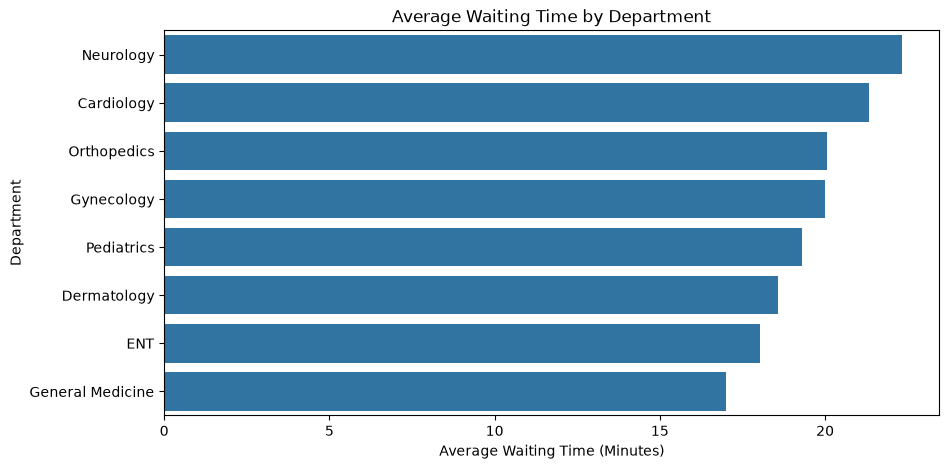

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=department_wait.values,
    y=department_wait.index
)

plt.title("Average Waiting Time by Department")
plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Department")

plt.show()

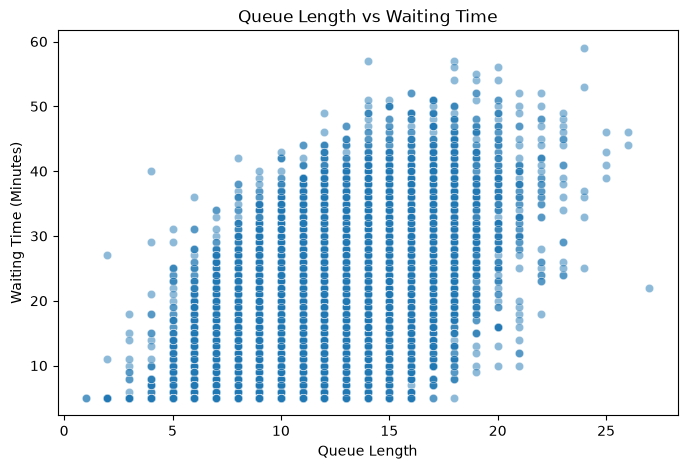

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Queue_Length",
    y="Waiting_Time_Minutes",
    alpha=0.5
)

plt.title("Queue Length vs Waiting Time")
plt.xlabel("Queue Length")
plt.ylabel("Waiting Time (Minutes)")

plt.show()

In [24]:
correlation = df[
    ["Queue_Length", "Waiting_Time_Minutes"]
].corr()

print(correlation)

                      Queue_Length  Waiting_Time_Minutes
Queue_Length              1.000000              0.528387
Waiting_Time_Minutes      0.528387              1.000000


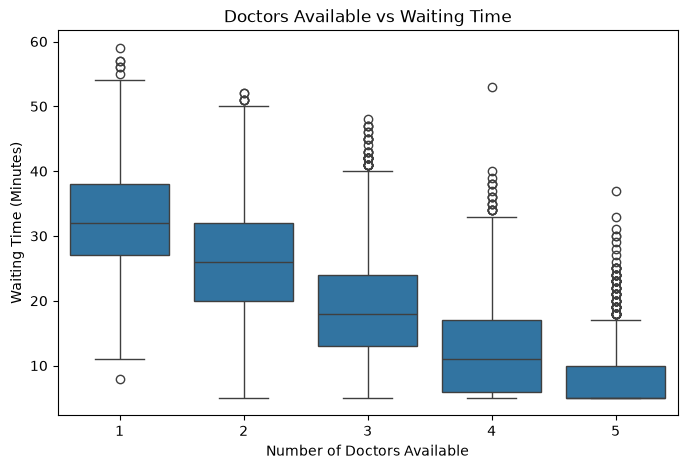

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Doctors_Available",
    y="Waiting_Time_Minutes"
)

plt.title("Doctors Available vs Waiting Time")
plt.xlabel("Number of Doctors Available")
plt.ylabel("Waiting Time (Minutes)")

plt.show()

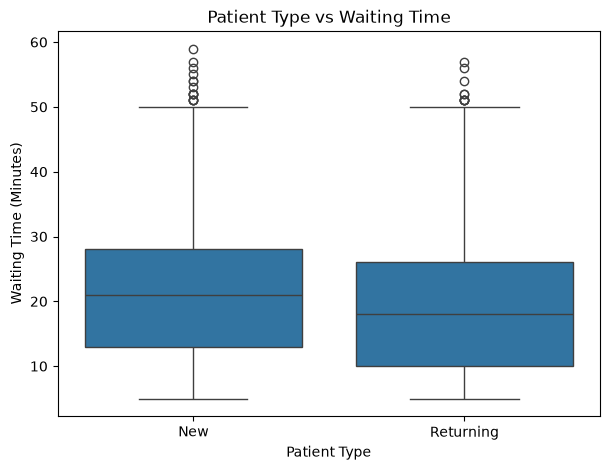

In [26]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Patient_Type",
    y="Waiting_Time_Minutes"
)

plt.title("Patient Type vs Waiting Time")
plt.xlabel("Patient Type")
plt.ylabel("Waiting Time (Minutes)")

plt.show()

In [27]:
numeric_columns = [
    "Queue_Length",
    "Doctors_Available",
    "Appointments_Count",
    "Consultation_Duration_Min",
    "Waiting_Time_Minutes"
]

correlation = df[numeric_columns].corr()

print(correlation)

                           Queue_Length  Doctors_Available  \
Queue_Length                   1.000000           0.010126   
Doctors_Available              0.010126           1.000000   
Appointments_Count             0.005434           0.001657   
Consultation_Duration_Min     -0.007487           0.005514   
Waiting_Time_Minutes           0.528387          -0.662461   

                           Appointments_Count  Consultation_Duration_Min  \
Queue_Length                         0.005434                  -0.007487   
Doctors_Available                    0.001657                   0.005514   
Appointments_Count                   1.000000                  -0.011226   
Consultation_Duration_Min           -0.011226                   1.000000   
Waiting_Time_Minutes                 0.106149                   0.211012   

                           Waiting_Time_Minutes  
Queue_Length                           0.528387  
Doctors_Available                     -0.662461  
Appointments_Count  

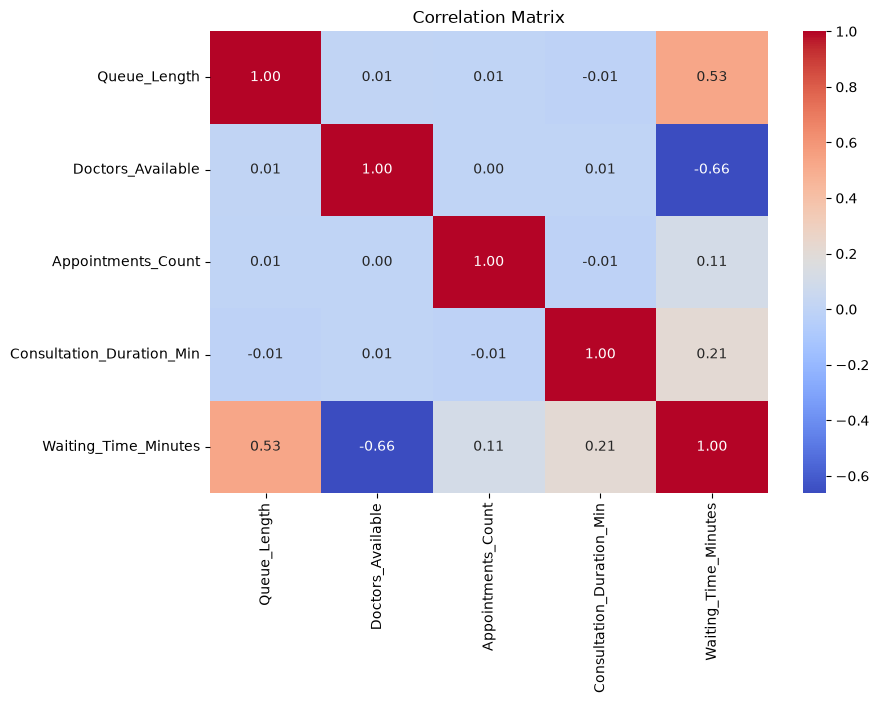

In [28]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [29]:
patient_wait = (
    df.groupby("Patient_Type")["Waiting_Time_Minutes"]
    .agg(["mean", "median", "min", "max"])
)

print(patient_wait)

                   mean  median  min  max
Patient_Type                             
New           21.072860    21.0    5   59
Returning     18.573093    18.0    5   57


In [30]:
doctor_wait = (
    df.groupby("Doctors_Available")["Waiting_Time_Minutes"]
    .mean()
)

print(doctor_wait)

Doctors_Available
1    32.314239
2    25.714238
3    18.717058
4    12.502010
5     8.397188
Name: Waiting_Time_Minutes, dtype: float64


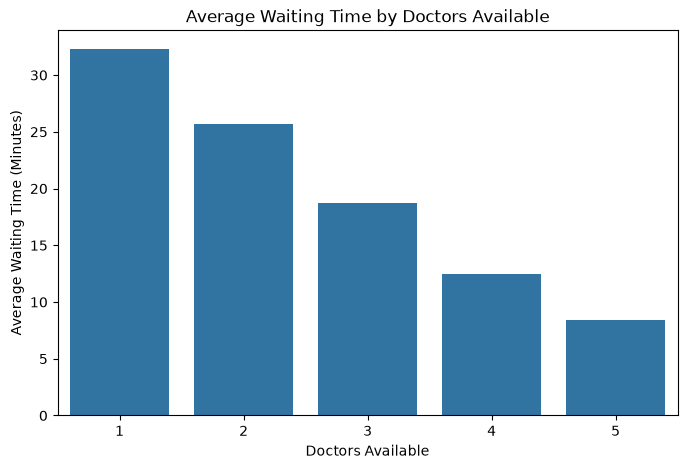

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=doctor_wait.index,
    y=doctor_wait.values
)

plt.title("Average Waiting Time by Doctors Available")
plt.xlabel("Doctors Available")
plt.ylabel("Average Waiting Time (Minutes)")

plt.show()

In [32]:
queue_wait = (
    df.groupby("Queue_Length")["Waiting_Time_Minutes"]
    .mean()
)

print(queue_wait)

Queue_Length
1      5.000000
2      8.500000
3      7.230769
4      8.000000
5      9.827338
6     10.790698
7     11.306667
8     13.349938
9     14.410873
10    16.867229
11    17.810213
12    19.151111
13    21.340854
14    22.359893
15    24.674365
16    26.195618
17    27.971983
18    29.846154
19    31.531429
20    33.892857
21    33.053571
22    36.181818
23    37.368421
24    40.500000
25    42.250000
26    45.000000
27    22.000000
Name: Waiting_Time_Minutes, dtype: float64


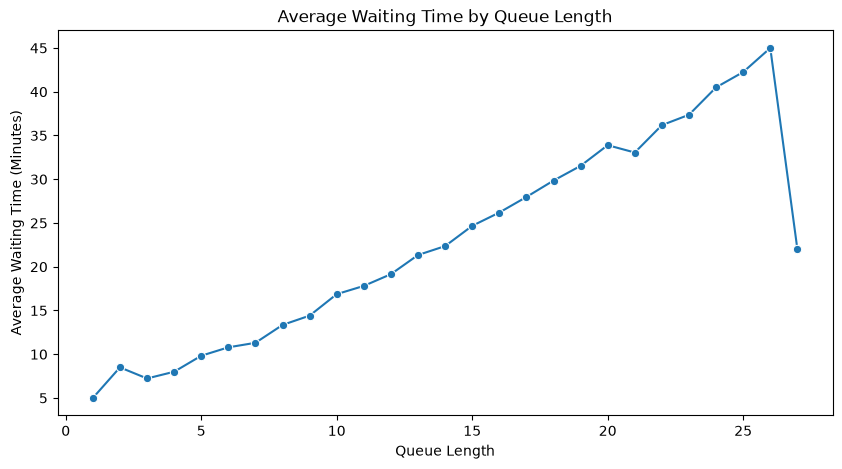

In [33]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=queue_wait.index,
    y=queue_wait.values,
    marker="o"
)

plt.title("Average Waiting Time by Queue Length")
plt.xlabel("Queue Length")
plt.ylabel("Average Waiting Time (Minutes)")

plt.show()